<span style="font-family:monospace;letter-spacing:.14em;color:#857259">BANA · MODULE 2 · EXPLORING AND VISUALISING DATA</span>

# Session 5: Relationships and the EDA brief

**Dataset:** EV purchase intention (Kaggle Playground Series S6E9, a *synthetic* dataset). You work with a 10,000-row seeded sample, `ev_m2_sample.csv`.
**Time:** 60 minutes. **Course outcomes:** CO2 (and CO3 for Session 5).

| Block | Min | What you do |
|---|---|---|
| Hook | 5 | Challenger: the right data shown the wrong way |
| Concept | 10 | Correlation: what it is and is not (instructor) |
| Guided lab | 30 | Correlation heatmap, binary-outcome plots, a confound |
| Team task | 10 | Project Charter v1 |
| Exit ticket | 5 | Three quick checks |

**By the end of this session you can:**
- read a correlation and say what it does not prove
- choose a better plot than a scatter when the outcome is yes/no
- check a pattern within sub-groups
- turn exploration into a one-page Project Charter

**New commands this session (max 5):** `df.corr()`, `sns.scatterplot`, `sns.heatmap` (reuse), `groupby` for sub-groups

**AI-use (AMBER protocol).** You may use an AI tool to look up *syntax*. The reasoning and interpretation must be your own: you will defend them in the viva.

## Facilitator notes: Session 5
**Question for the room:** *What moves together with buying, and what does that not prove?*

**Run of show**
1. **Hook (5):** Challenger, 1986. Engineers had O-ring damage data from earlier flights, but the chart they sent only showed flights *with* damage, hiding the pattern between low temperature and damage (Dalal, Fowlkes & Hoadley, 1989; Tufte, 1997). Same data, different chart, different decision.
2. **Concept (10):** correlation is a number between -1 and 1 for *straight-line, two-variable* association. It does not show cause. Include a 5-minute Simpson's / confound demo (Simpson, 1951; Pearl, 2014) using Part D.
3. **Lab (30):** Parts B to D.
4. **Team task (10):** Project Charter v1, from the template.

**What the data shows (sample of 10,000)**
- Correlation with buying: environmental concern **0.47**, income **0.23**; age, cars owned, and both charger counts are close to **0**.
- A scatter of income against a 0/1 outcome is two stripes of dots: the *wrong plot*. The Yes rate by income decile is the right one.
- Public charging stations near home correlate slightly *negatively* with buying, but only because dense urban areas have many stations and few home chargers. Correlation points to a lurking variable, not a cause.

**Honest limits.** The data is synthetic. Environmental concern correlating at about 0.47 is far stronger than most real surveys show; discuss that before students quote it as a market fact.

In [1]:
# -- Setup: run once ------------------------------------------------------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
warnings.filterwarnings("ignore")

# House style: Nikhil D Jonathan design system (sand ground, terracotta / lagoon / ochre data colours)
C = {"lagoon": "#25707B", "terracotta": "#B5562F", "ochre": "#E0A231", "moss": "#3F6F4B",
     "earth": "#665643", "ink": "#221B15", "sand": "#F8F3EA", "card": "#FFFDF9", "line": "#E3D6C1"}
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": C["sand"], "axes.facecolor": C["card"], "axes.edgecolor": "#CDBCA3",
    "grid.color": C["line"], "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "xtick.color": "#4A3E31", "ytick.color": "#4A3E31", "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left"})
PCT = PercentFormatter(1, decimals=0)                              # axis labels as percentages
SEQ = sns.light_palette(C["terracotta"], as_cmap=True)   # one-hue sequential map for heatmaps

# -- Load the data (Colab: upload ev_m2_sample.csv to the Files pane, or run the upload below)
FILE = "ev_m2_sample.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Choose ev_m2_sample.csv"); files.upload()
    except ImportError:
        raise FileNotFoundError("Put ev_m2_sample.csv in the same folder as this notebook.")
raw = pd.read_csv(FILE)
df = raw.copy()
print("Loaded", df.shape[0], "rows x", df.shape[1], "columns")

Loaded 10000 rows x 15 columns


## Part A. Setup

In [2]:
def add_derived(d):
    """The four derived columns built in Session 1 (pre-written so every notebook stands alone)."""
    d = d.copy()
    d["buy"] = (d["Will_Buy_EV"] == "Yes").astype(int)
    d["age_band"] = pd.cut(d["Age"], bins=[24, 34, 44, 54, 69], labels=["25-34", "35-44", "45-54", "55-69"])
    d["income_band"] = pd.qcut(d["Annual_Income_USD"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
    d["charger_total"] = d["Charging_Stations_Near_Home"] + d["Charging_Stations_Near_Work"]
    return d

In [3]:
def apply_s3_decisions(d):
    """Session 3 data-quality decisions, applied in one place (see your decision log)."""
    d = d.copy()
    d["income_was_missing"] = d["Annual_Income_USD"].isna()
    d["Annual_Income_USD"] = d["Annual_Income_USD"].fillna(d.groupby("City_Type")["Annual_Income_USD"].transform("median"))
    d["Daily_Commute_km"] = d["Daily_Commute_km"].fillna(d["Daily_Commute_km"].median())
    d = d.dropna(subset=["Environmental_Concern_Level"])      # strongest signal: do not blur it with a median
    d["income_at_floor"] = d["Annual_Income_USD"] == 30000
    d["commute_at_floor"] = d["Daily_Commute_km"] == 5
    return d

df = add_derived(apply_s3_decisions(raw))     # Session 3 decisions pre-applied
df["anxiety_score"] = df["Range_Anxiety_Level"].map({"Low": 0, "Medium": 1, "High": 2})    # ordered category as 0/1/2
print(df.shape)

(9806, 23)


## Part B. Correlation heatmap (10 min)
**Predict first:** write down the two columns you think correlate most strongly with `buy`.

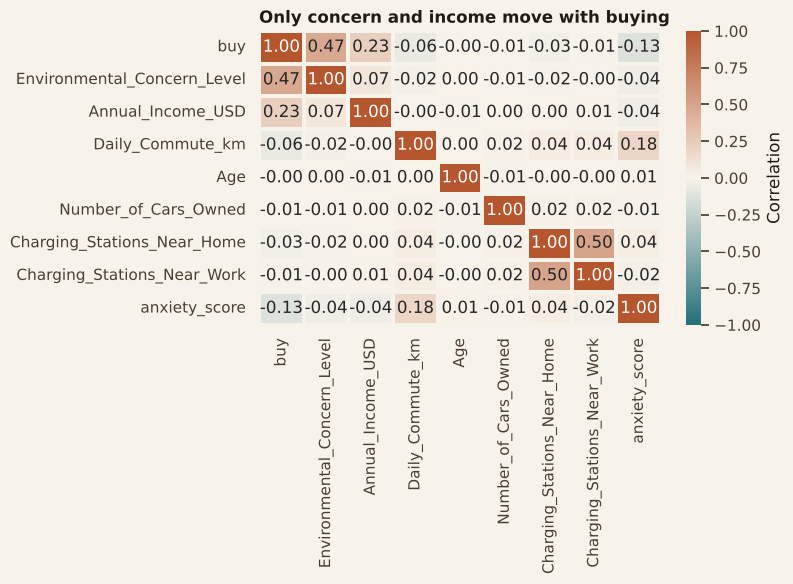

In [4]:
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list("div", [C["lagoon"], "#F8F3EA", C["terracotta"]])    # two hues + neutral middle
cols = ["buy", "Environmental_Concern_Level", "Annual_Income_USD", "Daily_Commute_km", "Age", "Number_of_Cars_Owned",
        "Charging_Stations_Near_Home", "Charging_Stations_Near_Work", "anxiety_score"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV, vmin=-1, vmax=1, center=0, linewidths=1.5, linecolor=C["sand"], cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Only concern and income move with buying")
plt.tight_layout()

In [5]:
corr['buy'].drop('buy').sort_values(ascending=False).round(2)

Environmental_Concern_Level    0.47
Annual_Income_USD              0.23
Age                           -0.00
Number_of_Cars_Owned          -0.01
Charging_Stations_Near_Work   -0.01
Charging_Stations_Near_Home   -0.03
Daily_Commute_km              -0.06
anxiety_score                 -0.13
Name: buy, dtype: float64

**YOUR ANSWER:** Which two columns correlate with `buy`? Which pairs of *other* columns are strongly related to each other? Is a correlation of 0.02 worth acting on?

> _write here_

**Expected:** concern (0.47) and income (0.23). The two charger counts relate to each other (about 0.5). Range anxiety correlates **negatively** (-0.13) and positively with commute length (about 0.18): longer commuters worry more about range. Near-zero values (age, cars owned) say there is no *straight-line* link; they do not rule out other patterns.

## Part C. When the outcome is yes/no, a scatter fails (8 min)

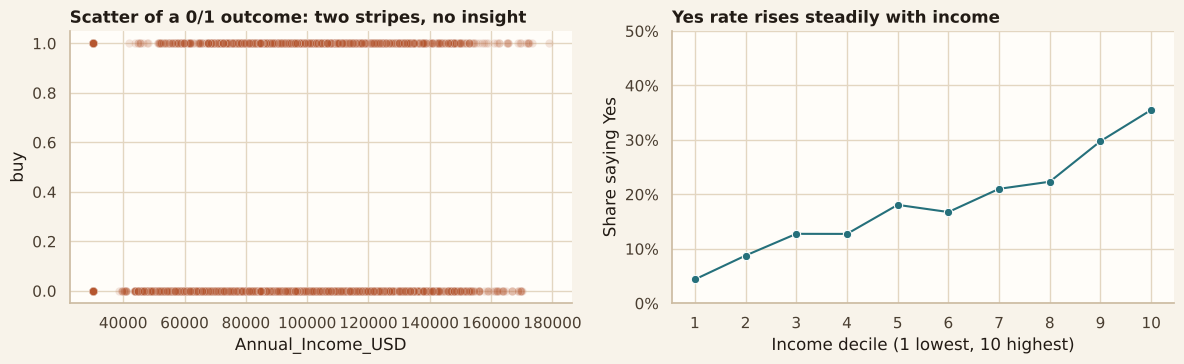

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.scatterplot(data=df, x="Annual_Income_USD", y="buy", alpha=0.15, color=C["terracotta"], ax=axes[0])
axes[0].set_title("Scatter of a 0/1 outcome: two stripes, no insight")
df["income_decile"] = pd.qcut(df["Annual_Income_USD"], 10, labels=False) + 1
dec = df.groupby("income_decile")["buy"].mean()
sns.lineplot(x=dec.index, y=dec.values, marker="o", color=C["lagoon"], ax=axes[1])
axes[1].set_xticks(range(1, 11)); axes[1].set_ylim(0, 0.5)
axes[1].set_xlabel("Income decile (1 lowest, 10 highest)"); axes[1].set_ylabel("Share saying Yes"); axes[1].yaxis.set_major_formatter(PCT)
axes[1].set_title("Yes rate rises steadily with income")
plt.tight_layout()

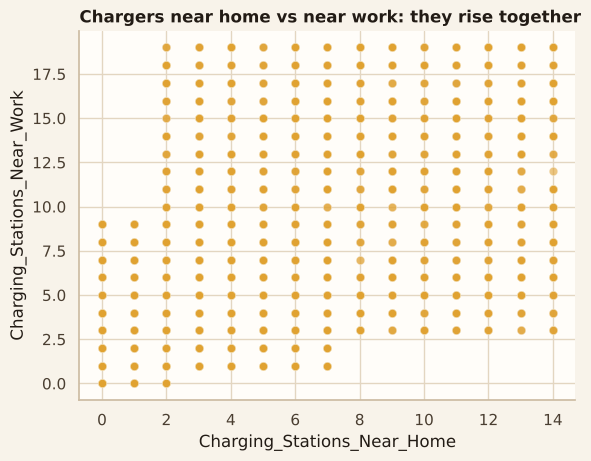

In [7]:
# Two number columns on the same scale: now a scatter makes sense
sns.scatterplot(data=df, x="Charging_Stations_Near_Home", y="Charging_Stations_Near_Work", alpha=0.2, color=C["ochre"])
plt.title("Chargers near home vs near work: they rise together");

## Part D. A correlation that is really something else (7 min)

In [8]:
overall = df["Charging_Stations_Near_Home"].corr(df["buy"])
print(f"Correlation of stations near home with buying (everyone): {overall:.3f}")
print(df.groupby("City_Type")["Charging_Stations_Near_Home"].mean().round(1).rename("average stations near home"))
print()
tbl = df.pivot_table(values="buy", index="Home_Charging_Possible", columns="City_Type", aggfunc="mean", observed=True).round(3)
tbl

Correlation of stations near home with buying (everyone): -0.026
City_Type
Rural       1.1
Suburban    3.4
Urban       7.9
Name: average stations near home, dtype: float64



City_Type,Rural,Suburban,Urban
Home_Charging_Possible,,,
No,0.091,0.081,0.137
Yes,0.220,0.197,0.206


**YOUR ANSWER:** More public chargers near home goes with *slightly lower* buying. Does that mean building chargers puts people off? What is the lurking variable? Use the table above.

> _write here_

**Expected:** no. Dense urban areas have many public stations (7.9 on average vs 1.1 rural) but few home chargers. The pattern follows *city type and home charging*, not the stations themselves. The correlation is tiny and should not be acted on.

## Team task: Project Charter v1 (10 min)
One page per team. Fill every blank in the cell below; the next modules will each add one section.

In [9]:
charter = {
    "1. Business question (one sentence, names a decision)": "____",
    "2. Target variable and base rate": "buy (Yes = 1); base rate = ____ %",
    "3. Hypothesis A (from Session 4)": "____",
    "4. Hypothesis B": "____",
    "5. Hypothesis C": "____",
    "6. Data risk 1 (from your Session 3 log)": "____",
    "7. Data risk 2": "____",
    "8. Data risk 3": "____",
    "9. Scope (what is IN / OUT)": "____",
    "10. Budget (person-hours)": "____",
    "11. Schedule (Modules 3 to 6, by week)": "____",
}
pd.Series(charter).to_frame("Your answer")

,Your answer
"1. Business question (one sentence, names a decision)",____
2. Target variable and base rate,buy (Yes = 1); base rate = ____ %
3. Hypothesis A (from Session 4),____
4. Hypothesis B,____
5. Hypothesis C,____
6. Data risk 1 (from your Session 3 log),____
7. Data risk 2,____
8. Data risk 3,____
9. Scope (what is IN / OUT),____
10. Budget (person-hours),____


**Where each hypothesis gets tested:**

| Module | What you will do with this charter |
|---|---|
| **M3** | Test hypotheses: t-test (income of Yes vs No), chi-square (Yes vs subsidy, city, home charging), ANOVA (income by city) |
| **M4** | Logistic regression on `buy`; linear regression on income or commute |
| **M5** | Train/test split, decision tree, confusion matrix, ROC-AUC; fairness check by gender and city (DPDP link) |
| **M6 (optional)** | K-Means on income, concern, commute, chargers; profile each cluster's Yes rate |

**Marking guide for the charter.** Business question names a decision (not "analyse EVs"); target and base rate correct (18.2%); each hypothesis names a column and a direction; risks come from the Session 3 log; scope and schedule are realistic. Good hypotheses from the data: *a subsidy is a precondition for Yes* (0.6% vs 28.5%); *higher environmental concern raises Yes only with a subsidy*; *the rural advantage is mostly home charging*.

## Exit ticket (5 min)
1. A correlation of 0.47 between concern and buying. Say what it means and what it does *not* mean.
2. Why is a scatter plot a poor choice for a yes/no outcome? What did we use instead?
3. Give one lurking variable from today's data.

**Answers:** (1) higher concern goes with a higher Yes rate; it does not show concern *causes* buying, and this synthetic data likely overstates the link; (2) the points collapse into two stripes; use the rate by bin; (3) city type / home charging behind the stations pattern.

**Viva prompt (AMBER):** "Pick one hypothesis in your charter. What evidence from Session 4 supports it, and what would make you drop it?"

### References (facilitator only)
Dalal, S. R., Fowlkes, E. B., & Hoadley, B. (1989). Risk analysis of the space shuttle: Pre-Challenger prediction of failure. *Journal of the American Statistical Association*, 84(408), 945-957.
Tufte, E. R. (1997). *Visual Explanations*. Graphics Press.
Simpson, E. H. (1951). The interpretation of interaction in contingency tables. *Journal of the Royal Statistical Society, Series B*, 13(2), 238-241.
Pearl, J. (2014). Understanding Simpson's paradox. *The American Statistician*, 68(1), 8-13.
Provost, F., & Fawcett, T. (2013). *Data Science for Business*. O'Reilly.
Hardman, S., et al. (2018). The effectiveness of financial purchase incentives for battery electric vehicles: A review of the evidence. *Renewable and Sustainable Energy Reviews*, 80, 1100-1111.
Franke, T., Neumann, I., Buhler, F., Cocron, P., & Krems, J. F. (2012). Experiencing range in an electric vehicle: Understanding psychological barriers. *Applied Psychology*, 61(3), 368-391.